# Import Library

In [ ]:
import numpy as np
from numpy import where
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from collections import Counter
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, SVMSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, NearMiss, TomekLinks
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline
from sklearn import clone
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score


# Soal

### **Ketentuan:**

1. Dokumen template lab dengan format .ipynb dan dataset (jika dibutuhkan) telah disediakan.
2. Jalankan kode pada dokumen .ipynb dan perhatikan dengan saksama apa yang potongan kode tersebut lakukan beserta dengan keluarannya. Jawablah **pertanyaan** yang disisipkan pada potongan program yang diberikan.
3. Dokumen Jupyter Notebook yang telah dilengkapi dengan jawaban dikumpulkan dalam sebuah repositori Git (misalnya, di GitHub atau GitLab) dan kirimkan tautannya kepada kami.
4. Sebelum di kumpulkan, kode **WAJIB** dijalankan.

## Deskripsi Dataset

Dataset yang akan dipakai pada soal ini adalah dataset [Bank Customer Churn](https://www.kaggle.com/datasets/radheshyamkollipara/bank-customer-churn) dengan sedikit modifikasi. Silahkan klik link tersebut untuk mengetahui penjelasan fitur-fiturnya.

Target variable pada dataset ini adalah `Exited`. Jumlah customer yang tidak meninggalkan bank (`Exited=0`) adalah 7962, sedangkan jumlah customer yang meninggalkan bank (`Exited=1`) adalah 159. Ini membuat dataset menjadi imbalance dan anda akan menangani kasus imbalance data tersebut.

In [ ]:
df=pd.read_csv('Customer-Churn-Records-v2.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8121 entries, 0 to 8120
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         8121 non-null   int64  
 1   Geography           8121 non-null   object 
 2   Gender              8121 non-null   object 
 3   Age                 8121 non-null   int64  
 4   Tenure              8121 non-null   int64  
 5   Balance             8121 non-null   float64
 6   NumOfProducts       8121 non-null   int64  
 7   HasCrCard           8121 non-null   int64  
 8   IsActiveMember      8121 non-null   int64  
 9   EstimatedSalary     8121 non-null   float64
 10  Exited              8121 non-null   int64  
 11  Complain            8121 non-null   int64  
 12  Satisfaction Score  8121 non-null   int64  
 13  Card Type           8121 non-null   object 
 14  Point Earned        8121 non-null   int64  
dtypes: float64(2), int64(10), object(3)
memory usage: 951.8

In [ ]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,757,Germany,Female,34,9,101861.36,2,0,0,187011.96,0,0,5,PLATINUM,903
1,644,France,Male,33,8,0.00,2,1,1,155294.17,0,0,5,SILVER,813
2,655,Spain,Female,56,5,0.00,2,1,1,41782.70,0,0,2,PLATINUM,979
3,710,Spain,Female,36,8,0.00,2,0,0,83206.19,0,0,3,SILVER,636
4,684,Spain,Female,31,8,0.00,2,1,0,188637.05,0,0,4,SILVER,515


In [ ]:
df['Exited'].value_counts()

,count
Exited,
0,7962
1,159


## 1. Imbalanced dataset

a) Buatlah sebuah dataset baru yang terdiri dari kolom `EstimatedSalary` dan kolom `Balance` sebagai fitur-fiturnya (X), dan kolom `Exited` sebagai target (y).

In [ ]:
# ini adalah bagian a
X = df[['EstimatedSalary', 'Balance']].values
y = df['Exited'].values

b) Hitung jumlah masing-masing target (Hint: Counter).

In [ ]:
#ini bagian b
Counter(y)

Counter({np.int64(0): 7962, np.int64(1): 159})

c) Visualisasikan dataset pada soal (1a) dengan scatter plot. Berikan warna yang berbeda untuk setiap kelasnya

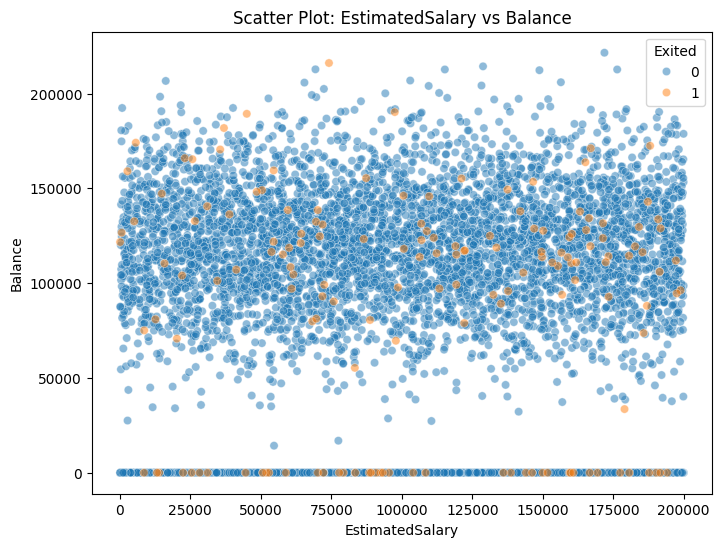

In [ ]:
#ini bagian c
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.scatterplot(x='EstimatedSalary', y='Balance', data=df, hue='Exited', alpha=0.5) #hue untuk untuk warna per kelas, alpha untuk biar titik kelas 1 yang sedikit tidak ketutupan.
plt.title('Scatter Plot: EstimatedSalary vs Balance')
plt.xlabel('EstimatedSalary')
plt.ylabel('Balance')
plt.show()

d) Lengkapilah fungsi di bawah ini untuk melakukan oversampling pada setiap fold ketika melakukan cross validation pada suatu model menggunakan StratifiedKFold dengan k=5, shuffle=True, dan random_state=42. Tampilkan juga rata-rata skor accuracy, f1 macro, precision macro, dan recall macro.

Jalankan fungsi tersebut dengan menggunakan:
- DecisionTreeClassifier, dengan random_state=42
- Teknik oversampling RandomOversampler, dengan random_state=42
- X dan y yang didefinisikan pada soal (1a)

*(Pastikan validation test dataset tidak terganggu oleh penambahan data - data sintetis.)*

In [ ]:
def train_and_evaluate_with_oversampling(model, X, y, resample_method):
    # TODO: Gunakan StratifiedK-fold biasa (Ubah None menjadi jawaban)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # TODO: Simpan hasil skor metrik setiap iterasi pada sebuah list
    accuracy_list = []
    f1_list = []
    precision_list = []
    recall_list = []
    # Iterasi untuk membagi fold mana yang menjadi training dan validation test dataset
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
        X_train = X[train_index]
        y_train = y[train_index]
        X_test = X[test_index]
        y_test = y[test_index]


        # TODO: Lakukan fit resample dari menggunakan variabel resample_method di parameter method ini (Ubah None menjadi jawaban)
        X_train_sampled, y_train_sampled = resample_method.fit_resample(X_train, y_train)

        model_clone = clone(model) # Cloning model untuk membuat model harus dilatih lagi untuk memprediksi di luar method ini

        # TODO: Lakukan fitting model dari hasil clone model dengan X dan y dataset yang sudah diresample
        model_clone.fit(X_train_sampled, y_train_sampled)

        # TODO: Prediksi kelas kategori menggunakan model yang telah dilatih di atas dengan menggunakan validation test dataset (Ubah None menjadi jawaban)
        y_pred = model_clone.predict(X_test)
        # TODO: Hitung dan tampilkan skor metrik yang diinginkan

        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="macro")
        precision = precision_score(y_test, y_pred, average="macro")
        recall = recall_score(y_test, y_pred, average="macro")

        # TODO: Tambahkan hasil skor metrik ke dalam list yang bersesuaian
        accuracy_list.append(accuracy)
        f1_list.append(f1)
        precision_list.append(precision)
        recall_list.append(recall)

    # TODO: Hitung dan tampilkan mean dari setiap list skor metrik
    # Notes: ganti None dengan nama variabel list masing - masing metrik

    print("Mean scores across all folds:")
    print(f'Mean Accuracy: {np.mean(accuracy_list)}')
    print(f'Mean F1-score (macro): {np.mean(f1_list)}')
    print(f'Mean Precision (macro): {np.mean(precision_list)}')
    print(f'Mean Recall (macro): {np.mean(recall_list)}')

In [ ]:
train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, RandomOverSampler(random_state=42))

Mean scores across all folds:
Mean Accuracy: 0.9635509662751043
Mean F1-score (macro): 0.4976120916265085
Mean Precision (macro): 0.497570140331623
Mean Recall (macro): 0.49772234982701613


e) Jalankan kode di bawah ini. Apakah terdapat perbedaan skor dengan yang ada pada soal (1d)? Jika berbeda, mengapa hal tersebut bisa terjadi, dan approach manakah yang lebih tepat untuk dilakukan (approach (1d) atau (1e))?

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_oversampled, y_oversampled = RandomOverSampler(random_state=42).fit_resample(X, y)

scoring = ['accuracy','f1_macro', 'precision_macro', 'recall_macro']
for i in range(len(scoring)):
  score = cross_val_score(DecisionTreeClassifier(random_state=42), X_oversampled, y_oversampled, scoring=scoring[i], cv=cv, n_jobs=-1)
  print(f"{scoring[i]} score: {np.mean(score)}")

accuracy score: 0.9889476030071865
f1_macro score: 0.9889460502661436
precision_macro score: 0.9891971322065523
recall_macro score: 0.9889470500651404


Ada perbedaan besar: F1 macro 1d sekitar 0,50, sedangkan 1e sekitar 0,99. Pada 1e, oversampling dilakukan sebelum data dibagi menjadi fold, sehingga salinan data kelas 1 masuk ke data latih sekaligus data uji dan model cukup menghafalnya (data leakage). Approach yang lebih tepat adalah 1d, karena oversampling hanya dilakukan pada data latih di setiap fold sehingga data uji tetap asli.

Referensi:

[imbalanced-learn: Common pitfalls](https://imbalanced-learn.org/stable/common_pitfalls.html)
Santos, M. S., et al. (2018). Cross-Validation for Imbalanced Datasets: Avoiding Overoptimistic and Overfitting Approaches. IEEE Computational Intelligence Magazine, 13(4), 59–76. https://doi.org/10.1109/MCI.2018.2866730

f) Mengapa StratifiedKFold umumnya lebih sering digunakan dalam kasus Imbalanced dataset dibandingkan KFold biasa? Jelaskan serta berikan sumber referensi anda.

jawaban f: Karena StratifiedKFold menjaga perbandingan kelas di setiap fold agar sama dengan data keseluruhan, sedangkan KFold biasa membagi data tanpa melihat kelasnya. Di dataset ini, kelas 1 hanya sekitar 2% (159 dari 8121 data). Kalau memakai KFold biasa, bisa aja ada fold yang hanya berisi sedikit data kelas 1, atau malah tidak ada sama sekali, sehingga skor di tiap fold menjadi tidak stabil. Dengan StratifiedKFold, setiap fold uji pasti berisi sekitar 32 data kelas 1, sehingga hasil evaluasinya lebih bisa dipercaya.

referensi:
[scikit-learn: Stratified k-fold](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold)

## 2. Oversampling

a) Terapkan metode oversampling yang paling sesuai menurut anda dan bisa diterapkan dengan dataset soal (1a). Visualisasikan scatter plot hasil resampling datasetnya

Counter({np.int64(0): 7962, np.int64(1): 7962})


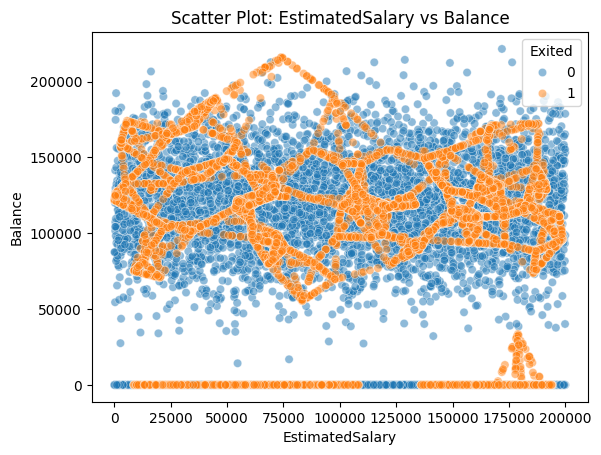

In [ ]:
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)
print(Counter(y_smote))
df_smote = pd.DataFrame(X_smote, columns=['EstimatedSalary', 'Balance'])
df_smote['Exited'] = y_smote
sns.scatterplot(x='EstimatedSalary', y='Balance', data=df_smote, hue='Exited', alpha=0.5) #hue untuk untuk warna per kelas, alpha untuk biar titik kelas 1 yang sedikit tidak ketutupan.
plt.title('Scatter Plot: EstimatedSalary vs Balance')
plt.xlabel('EstimatedSalary')
plt.ylabel('Balance')
plt.show()

b) Terapkan metode oversampling yang lain yang berbeda dengan metode pada soal (2a). Visualisasikan scatter plot hasil resampling datasetnya

Counter({np.int64(0): 7962, np.int64(1): 7962})


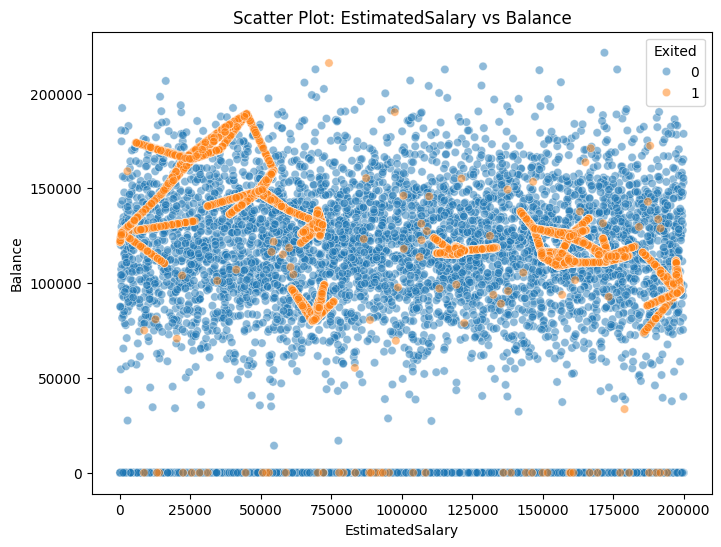

In [ ]:
borderline_smote = BorderlineSMOTE(random_state=42)
X_borderline_smote, y_borderline_smote = borderline_smote.fit_resample(X, y)
print(Counter(y_borderline_smote))
df_borderline_smote = pd.DataFrame(X_borderline_smote, columns=['EstimatedSalary', 'Balance'])
df_borderline_smote['Exited'] = y_borderline_smote

plt.figure(figsize=(8, 6))
sns.scatterplot(x='EstimatedSalary', y='Balance', data=df_borderline_smote, hue='Exited', alpha=0.5)
plt.title('Scatter Plot: EstimatedSalary vs Balance')
plt.xlabel('EstimatedSalary')
plt.ylabel('Balance')
plt.show()

c) Adakah perbedaan yang Anda temukan dari pengamatan terhadap data hasil kedua metode oversampling yang Anda pilih? Jika ada, jelaskan mengapa perbedaan tersebut bisa terjadi! Sertakan sumber referensi anda

jawabannya c : Terdapat perbedaan. Titik sintetis SMOTE tersebar hampir di seluruh area, sedangkan titik sintetis BorderlineSMOTE hanya terkumpul di beberapa jalur. Ini karena SMOTE memakai semua data kelas 1 sebagai dasar titik baru, sedangkan BorderlineSMOTE hanya memakai data kelas 1 yang berada di perbatasan dengan kelas 0. Data kelas 1 yang seluruh tetangganya kelas 0 dianggap noise dan tidak dipakai, dan karena kelas 1 di data ini sangat bercampur, hanya sedikit yang memenuhi syarat.

referensi:
Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P.

*   (2002). SMOTE: Synthetic Minority Over-sampling Technique. Journal of Artificial Intelligence Research, 16, 321–357. https://doi.org/10.1613/jair.953
*   Han, H., Wang, W. Y., & Mao, B. H. (2005). Borderline-SMOTE: A New Over-Sampling Method in Imbalanced Data Sets Learning. ICIC 2005, Lecture Notes in Computer Science, vol. 3644, 878–887. https://doi.org/10.1007/11538059_91




d) Lakukan cross validation menggunakan StratifiedKFold dengan k=5 pada 2 buah model Decision Tree yang berbeda dengan ketentuan berikut:
- Model pertama menggunakan metode oversampling yang dipakai pada (2a)
- Model kedua menggunakan metode oversampling yang dipakai pada (2b)
- Metrik utama yang digunakan adalah f1 macro.
- Oversampling dilakukan pada setiap fold cross validation

Petunjuk: Anda bisa menggunakan cara 1d untuk menjawab soal ini.

*(Pastikan validation test dataset tidak terganggu oleh penambahan data - data sintetis.)*

In [ ]:
# model smote
train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, smote)

Mean scores across all folds:
Mean Accuracy: 0.7194924592648732
Mean F1-score (macro): 0.4388088244142233
Mean Precision (macro): 0.5020141611930754
Mean Recall (macro): 0.5208467622369588


In [ ]:
# model borderline smote
train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, borderline_smote)

Mean scores across all folds:
Mean Accuracy: 0.9295630162940508
Mean F1-score (macro): 0.49750155401498464
Mean Precision (macro): 0.5013839571527866
Mean Recall (macro): 0.5018242801471668


e) Metode manakah yang memberikan skor F1 makro tertinggi? Jelaskan mengapa hal tersebut bisa terjadi.

BorderlineSMOTE menghasilkan F1-score macro sebesar 0,4975, lebih tinggi daripada SMOTE (0,4388). SMOTE menghasilkan data sintetis kelas 1 di area yang lebih luas, sedangkan BorderlineSMOTE berfokus pada sampel kelas 1 yang berada di dekat batas antarkelas. Perbedaan F1-score terjadi karena BorderlineSMOTE berfokus menambahkan data sintetis di dekat batas antarkelas, sehingga berpotensi membantu model mengenali kelas minoritas dengan lebih baik dibandingkan SMOTE.

## 3. Undersampling

a) Terapkan metode undersampling yang paling sesuai menurut anda dan bisa diterapkan dengan dataset soal (1a). Visualisasikan scatter plot hasil resampling datasetnya

Counter({np.int64(0): 159, np.int64(1): 159})


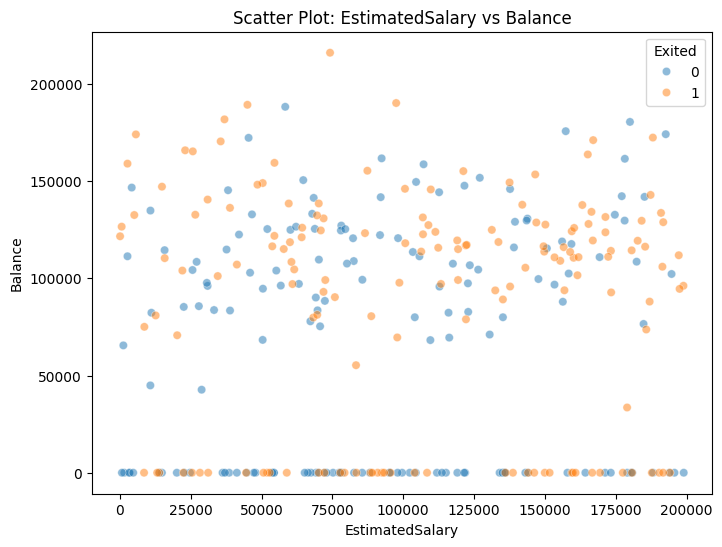

In [ ]:
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X, y)
print(Counter(y_rus))
df_rus = pd.DataFrame(X_rus, columns=['EstimatedSalary', 'Balance'])
df_rus['Exited'] = y_rus

plt.figure(figsize=(8, 6))
sns.scatterplot(x='EstimatedSalary', y='Balance', data=df_rus, hue='Exited', alpha=0.5)
plt.title('Scatter Plot: EstimatedSalary vs Balance')
plt.xlabel('EstimatedSalary')
plt.ylabel('Balance')
plt.show()

b) Terapkan metode undersampling lain yang berbeda dengan metode pada soal (3a). Visualisasikan scatter plot hasil resampling datasetnya

Counter({np.int64(0): 159, np.int64(1): 159})


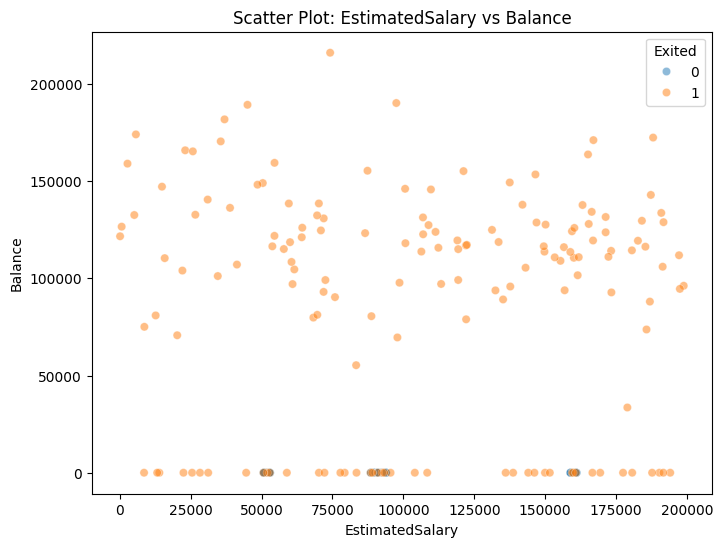

In [ ]:
nearmiss = NearMiss()
X_nearmiss, y_nearmiss = nearmiss.fit_resample(X, y)
print(Counter(y_nearmiss))
df_nearmiss = pd.DataFrame(X_nearmiss, columns=['EstimatedSalary', 'Balance'])
df_nearmiss['Exited'] = y_nearmiss

plt.figure(figsize=(8, 6))
sns.scatterplot(x='EstimatedSalary', y='Balance', data=df_nearmiss, hue='Exited', alpha=0.5)
plt.title('Scatter Plot: EstimatedSalary vs Balance')
plt.xlabel('EstimatedSalary')
plt.ylabel('Balance')
plt.show()

c) Berdasarkan visualisasi scatter plot kedua dataset hasil resampling pada soal (3a) dan (3b) yang Anda pilih, apa perbedaan yang terlihat? Jelaskan juga mengapa perbedaan tersebut bisa terjadi! Jangan lupa sertakan sumber referensi anda

Ada perbedaan. Data kelas 0 hasil RandomUnderSampler tetap tersebar merata, sedangkan hasil NearMiss terkumpul semua di garis `Balance = 0`. Ini karena RandomUnderSampler membuang data kelas 0 secara acak, sedangkan NearMiss memilih data kelas 0 yang paling dekat dengan data kelas 1, dan banyak data kelas 1 berada di garis `Balance = 0`.

**Referensi:**

1. Mani, I., & Zhang, I. (2003). *kNN Approach to Unbalanced Data Distributions: A Case Study Involving Information Extraction*. ICML 2003 Workshop on Learning from Imbalanced Datasets.
2. [imbalanced-learn: NearMiss](https://imbalanced-learn.org/stable/under_sampling.html#controlled-under-sampling-techniques)

d) Lakukan cross validation menggunakan StratifiedKFold dengan k=5 pada 2 buah model Decision Tree yang berbeda dengan ketentuan berikut:
- Model pertama menerima dataset pada soal (3a)
- Model kedua menerima dataset pada soal (3b)
- Metrik utama yang digunakan adalah f1 macro.

In [ ]:
#Model RandomUnderSampler
train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, rus)

Mean scores across all folds:
Mean Accuracy: 0.4987067828723001
Mean F1-score (macro): 0.3500189857955057
Mean Precision (macro): 0.5007765595128328
Mean Recall (macro): 0.5103098431249661


In [ ]:
#Model nearmiss
train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, nearmiss)

Mean scores across all folds:
Mean Accuracy: 0.06095460401667298
Mean F1-score (macro): 0.06035484672218348
Mean Precision (macro): 0.5011109151499873
Mean Recall (macro): 0.5026262035197757


e) Metode manakah yang memberikan skor F1 makro tertinggi? Jelaskan mengapa hal tersebut bisa terjadi.

F1 macro tertinggi diperoleh RandomUnderSampler (0,35), jauh di atas NearMiss (0,06). NearMiss memilih data kelas mayoritas berdasarkan kedekatannya dengan kelas minoritas, sehingga data kelas 0 yang dipertahankan hanya berasal dari garis `Balance = 0` (terlihat pada plot 3b) dan sebarannya menjadi kurang representatif. Akibatnya, model kesulitan mengenali kelas 0 dan menebak hampir semua data lain sebagai kelas 1, terlihat dari accuracy-nya yang hanya 0,06. Sebaliknya, RandomUnderSampler memilih data kelas mayoritas secara acak sehingga sebaran data yang dipertahankan lebih beragam, dan performanya lebih baik daripada NearMiss.

## 4. Cost-Sensitive Learning

a) Buatlah beberapa model decision tree dengan random_state=42 yang menerima dataset soal (1a) dan dengan weight yang berbeda, yaiu:
- tanpa weights
- weights = {0: 1, 1: 2}
- weights = {0: 1, 1: 99}

Lakukan train_test_split dengan ketentuan berikut:
- menggunakan X dan y dari soal (1a)
- stratify=y
- random_state=42
- test_size=0.2

Kemudian, lakukan fit predict pada model dengan weights yang berbeda, kemudian tampilkan skor f1 macro dan juga confusion matrix untuk masing-masing model DT dengan weights yang berbeda tersebut. Berikan label pada Confusion matrix nya

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size = 0.2, random_state = 42)

In [ ]:
#tanpa weight
dt_no_weight = DecisionTreeClassifier(random_state=42)
dt_no_weight.fit(X_train, y_train)
y_pred_no_weight = dt_no_weight.predict(X_test)
print(f1_score(y_test, y_pred_no_weight, average='macro'))

0.49059561128526646


In [ ]:
#weights = {0: 1, 1: 2}
dt_no_weight2 = DecisionTreeClassifier(random_state=42, class_weight={0: 1, 1: 2})
dt_no_weight2.fit(X_train, y_train)
y_pred_no_weight2 = dt_no_weight2.predict(X_test)
print(f1_score(y_test, y_pred_no_weight2, average='macro'))

0.49011609664261063


In [ ]:
#weights = {0: 1, 1: 99}
dt_no_weight3 = DecisionTreeClassifier(random_state=42, class_weight={0: 1, 1: 99})
dt_no_weight3.fit(X_train, y_train)
y_pred_no_weight3 = dt_no_weight3.predict(X_test)
print(f1_score(y_test, y_pred_no_weight3, average='macro'))

0.48947533773169966


b) Berdasarkan jawaban pada soal (4a), Apakah terdapat perbedaan pada confusion matrix dan score f1 macro masing-masing weights? Jelaskan.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

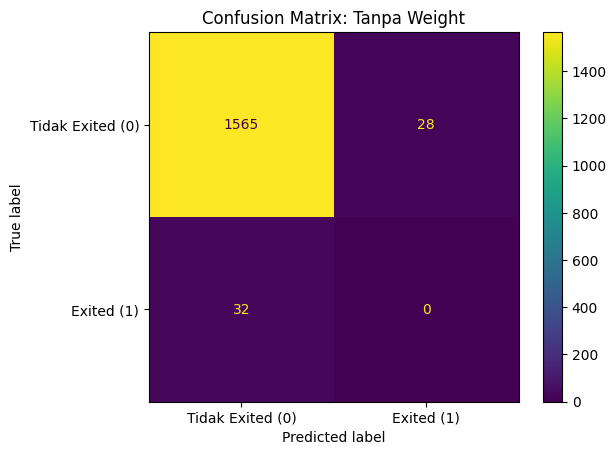

In [ ]:
#cunfusion matrix model pertama
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_no_weight, display_labels=['Tidak Exited (0)', 'Exited (1)'])
plt.title('Confusion Matrix: Tanpa Weight')
plt.show()

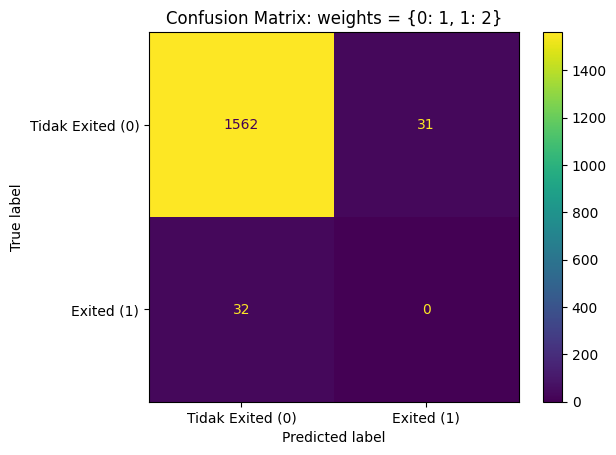

In [ ]:
#confusion matrix model kedua
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_no_weight2, display_labels=['Tidak Exited (0)', 'Exited (1)'])
plt.title('Confusion Matrix: weights = {0: 1, 1: 2}')
plt.show()

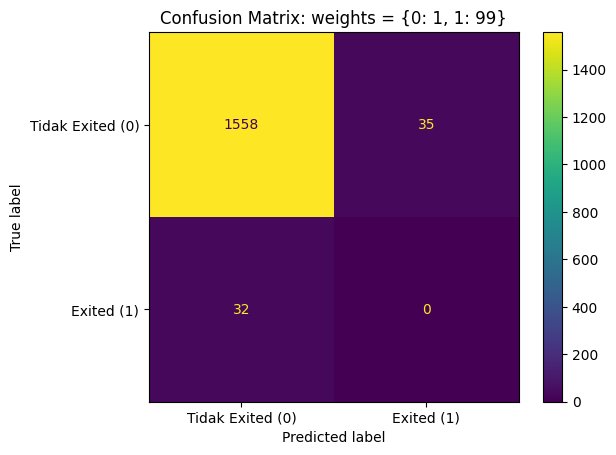

In [ ]:
#confusion matrix model ketiga
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_no_weight3, display_labels=['Tidak Exited (0)', 'Exited (1)'])
plt.title('Confusion Matrix: weights = {0: 1, 1: 99}')
plt.show()

## 5. Neural Network dan Pipeline

a) Buatlah sebuah model MLPClassifier dengan kriteria sebagai berikut:
- Memiliki 3 hidden layer dengan masing - masing layer terdiri dari 50, 40, dan 20 berturut - turut
- Menggunakan random_state=42
- Abaikan hyperparameter lain

In [ ]:
mlp_a = MLPClassifier(hidden_layer_sizes=(50, 40, 20), random_state=42)

b) Buatlah sebuah model MLPClassifier dengan kriteria sebagai berikut:
- Memiliki 2 hidden layer dengan masing - masing layer terdiri dari 100 dan 80 berturut - turut
- Menggunakan random_state=42
- Abaikan hyperparameter lain

In [ ]:
mlp_b = MLPClassifier(hidden_layer_sizes=(100, 80), random_state=42)

c) Lakukan cross validation menggunakan **Stratified K-fold** dengan k=5 dan random_state=42 terhadap kedua model MLP pada soal (5a) dan (5b) memakai X dan y yang didefinisikan pada soal (1a). Metrik evaluasi yang digunakan adalah f1 macro dan f1 micro. Tampilkan hasil rata-rata dari metriknya

In [ ]:
#model mlp_a
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'f1_micro']
for i in range(len(scoring)):
  score = cross_val_score(mlp_a, X, y, scoring=scoring[i], cv=cv, n_jobs=-1)
  print(f"{scoring[i]} score: {np.mean(score)}")

f1_macro score: 0.49429752710835856
f1_micro score: 0.977465479348238


In [ ]:
#model mlp_b
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'f1_micro']
for i in range(len(scoring)):
  score = cross_val_score(mlp_b, X, y, scoring=scoring[i], cv=cv, n_jobs=-1)
  print(f"{scoring[i]} score: {np.mean(score)}")

f1_macro score: 0.495056888197649
f1_micro score: 0.9804211443728686


d) Apakah terdapat perbedaan skor metrik makro evaluasi model pada soal (5c)? Jelaskan keterkaitan perbedaan skor dengan perbedaan hyperparameter kedua model!

terdapat perbedaan, di model mlp_a f1_macro scorenya 0.494 kalau model mlp_b 0.495. Perbedaannya sangat kecil sehingga perbedaan hyperparameter `hidden_layer_sizes` hampir tidak berpengaruh. mlp_b yang memiliki 2 hidden layer dengan neuron lebih banyak (100 dan 80) menebak semua data sebagai kelas 0, terlihat dari f1_micro-nya (0.980) yang sama persis dengan proporsi kelas 0 di data. mlp_a yang memiliki 3 hidden layer dengan neuron lebih sedikit (50, 40, dan 20) sempat menebak beberapa data sebagai kelas 1, tetapi semuanya salah, sehingga f1_macro-nya sedikit lebih rendah. Kedua model tidak mampu mengenali kelas 1 karena dua fitur yang dipakai memang tidak dapat memisahkan kelas 0 dan kelas 1, ditambah lagi fitur tidak di-scaling padahal nilainya mencapai ratusan ribu, sedangkan MLP sensitif terhadap skala fitur.


e) Dengan menggunakan Pipeline, lakukan cross validation menggunakan **Stratified K-fold** dengan k=5 dan random_state=42 pada sebuah pipeline yang berisi steps yaitu oversampling menggunakan SMOTE dengan random_state=42 dan menggunakan model MLP yang memiliki performa lebih bagus dari soal (5a) dan (5b). Gunakan X dan y yang didefinisikan pada soal (1a) untuk melakukan cross validation. Metrik evaluasi yang digunakan adalah f1 macro dan f1 micro. Tampilkan hasil rata-rata dari metriknya

In [ ]:
pipeline_smote = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('mlp', mlp_b)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'f1_micro']
for i in range(len(scoring)):
  score = cross_val_score(pipeline_smote, X, y, scoring=scoring[i], cv=cv, n_jobs=-1)
  print(f"{scoring[i]} score: {np.mean(score)}")

f1_macro score: 0.3715479594222225
f1_micro score: 0.5982022735884805


f) Dengan menggunakan Pipeline, lakukan cross validation menggunakan **Stratified K-fold** dengan k=5 dan random_state=42 pada sebuah pipeline yang berisi steps yaitu undersampling menggunakan RandomUnderSampler dengan random_state=42 dan menggunakan model MLP yang memiliki performa lebih bagus dari soal (5a) dan (5b). Gunakan X dan y yang didefinisikan pada soal (1a) untuk melakukan cross validation. Metrik evaluasi yang digunakan adalah f1 macro dan f1 micro. Tampilkan hasil rata-rata dari metriknya

In [ ]:
pipeline_rus = Pipeline([
    ('rus', RandomUnderSampler(random_state=42)),
    ('mlp', mlp_b)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'f1_micro']
for i in range(len(scoring)):
  score = cross_val_score(pipeline_rus, X, y, scoring=scoring[i], cv=cv, n_jobs=-1)
  print(f"{scoring[i]} score: {np.mean(score)}")

f1_macro score: 0.2963299574316605
f1_micro score: 0.5151358090185676


## 6. Soal Teoritis Neural Network

a) Apabila dalam binary classification dibutuhkan 1 neuron dalam output layer, berapa neuron yang dibutuhkan dalam output layer untuk multiclass classification? Berikan contoh dan sertakan sumber referensi yang kalian gunakan.

Jumlah neuron di output layer untuk multiclass classification sama dengan jumlah kelasnya, dengan fungsi aktivasi softmax. Softmax mengubah nilai setiap neuron menjadi probabilitas yang totalnya 1, lalu kelas dengan probabilitas tertinggi dipilih sebagai prediksi. Contohnya, klasifikasi bunga Iris dengan 3 kelas (setosa, versicolor, virginica) membutuhkan 3 neuron, sedangkan klasifikasi angka tulisan tangan 0–9 membutuhkan 10 neuron.

Referensi:
- [scikit-learn: Neural network models (supervised), bagian Classification](https://scikit-learn.org/stable/modules/neural_networks_supervised.html#classification)
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*, Bab 6.2.2.3 Softmax Units for Multinoulli Output Distributions. MIT Press. https://www.deeplearningbook.org/contents/mlp.html

b) Diketahui terdapat hyperparameter berikut pada MLPClassifier:
- hidden_layer_sizes
- learning_rate_init

Untuk masing-masing hyperparameter tersebut, jelaskan apa yang akan terjadi jika kita menetapkan value yang berbeda (misalnya menjelaskan perbedaan hidden_layer_size=(50,50) vs (100,50), dsb.). Asumsikan hyperparameter learning_rate yang dipakai adalah constant.

Sertakan sumber referensi anda.

**hidden_layer_sizes** mengatur jumlah hidden layer dan jumlah neuron di setiap layer. Misalnya (50, 50) berarti 2 hidden layer dengan 50 neuron di masing-masing layer, sedangkan (100, 50) berarti layer pertama berisi 100 neuron. Semakin banyak layer atau neuron, semakin banyak bobot yang dipelajari, sehingga model mampu menangkap pola yang lebih rumit. Kekurangannya, waktu training lebih lama dan model lebih mudah overfitting, terutama jika datanya sedikit. Sebaliknya, jika terlalu sedikit, model bisa underfitting karena tidak cukup mampu mempelajari pola data.

**learning_rate_init** mengatur besar langkah perubahan bobot di setiap iterasi (berlaku untuk solver `sgd` dan `adam`). Karena learning_rate diasumsikan constant, nilai ini tetap sama selama training. Jika terlalu besar, misalnya 0.1, perubahan bobot terlalu jauh sehingga loss naik-turun dan model sulit konvergen. Jika terlalu kecil, misalnya 0.00001, training berjalan sangat lambat dan bisa berhenti di `max_iter` sebelum konvergen. Nilai bawaannya 0.001.

Referensi:
- [scikit-learn: MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*, Bab 11.4.1 Manual Hyperparameter Tuning. MIT Press. https://www.deeplearningbook.org/contents/guidelines.html